## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
# read the dataset
data = pd.read_csv(r"datasets\amz_uk_price_prediction_dataset.csv") # read csv file

df = pd.DataFrame(data.copy())                                      # copying the file to have a raw file that stays like it is and a copy to work with

print(df.shape)                                                     # showing the shape of the dataset -> count of rows/columns

df.head()                                                           # showing first rows to validate that there is the correct data inside the file

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?



**Conclusion part 1:**

- 1. Displaying all the categories in one chart is possible but not recommended, because it is not meaningful, as nothing can be seen.
- 2. The category "Sports & Outdoors" is by far the most common.

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [16]:
frequency_categories = pd.DataFrame(df["category"].value_counts())  # creating a frequency table for the most popular product categories

display(frequency_categories[0:5])                                  # displaying the 5 most listed product categories

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

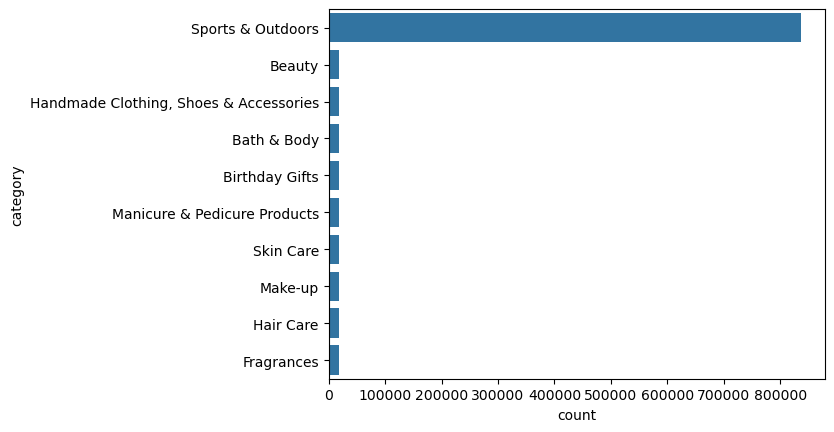

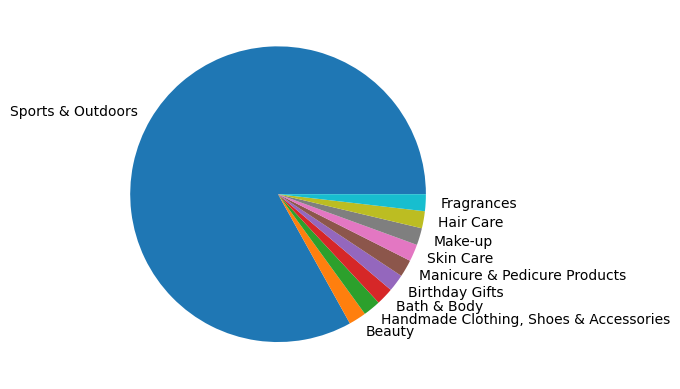

In [ ]:
#sns.countplot(data=df, x="category", palette="magma")                              # plot the count of all categories directly from dataset
#plt.show()

count_plot = 10                                                                             # select how many categories to plot in charts

sns.barplot(y="category", x="count", data=frequency_categories[:count_plot])               # plot the count of top 20 categories as bar chart
plt.show()

labels_categories = [frequency_categories.index[x]for x in range(count_plot)]                # extract categories to show them as labels in pie chart
plt.pie(data=frequency_categories[:count_plot], x="count", labels = labels_categories)      # plot the count of top 5 categories as pie chart
plt.show()



### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?



**Conclusion part 2:**

- 1. The average price point of products listed is 89.24. The most common one is 9.99 -> this is significantly lower than the average price
- 2. The range of product prizes (0 - 100000) is very huge. Also the price is very skewed when it comes to higher prices. Maybe there are some outliers.
- 3. histogram: Choosing only prices that are close to the average (i.e. < 1000) and choosing the bins parameter wisely is very useful.
- 3. barplot:   There are two extreme outliers at a price of 80000 and 100000. 

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [82]:
price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()

print(f"mean: {price_mean}")
print(f"median: {price_median}")
print(f"mode: {price_mode}")


mean: 89.24380943923661
median: 19.09
mode: 0    9.99
Name: price, dtype: float64


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [92]:
price_var = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()
#price_min = df["price"].min()
#price_max = df["price"].max()
price_interquartile_range = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print(f"variance: {price_var}")
print(f"standard deviation: {price_std}")
print(f"range: {price_range}")
#print(f"min: {price_min}")
#print(f"max: {price_max}")
print(f"interquartile range: {price_interquartile_range}")


print(price_std/price_mean)
round(float(df["price"].skew()), 2)

variance: 119445.48532256528
standard deviation: 345.60886175352226
range: 100000.0
interquartile range: 36.0
3.8726368128518405


27.49

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

<Axes: xlabel='price', ylabel='Count'>

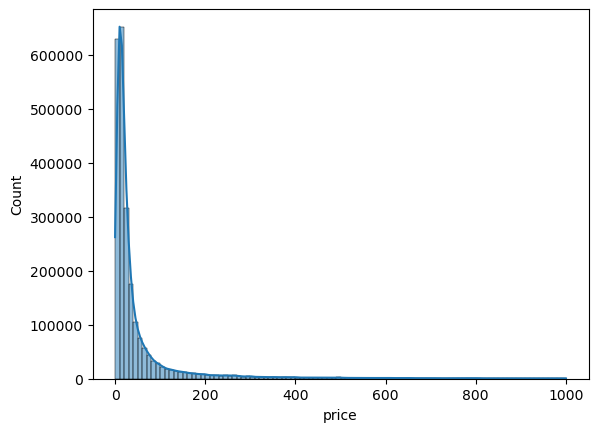

In [ ]:

sns.histplot(x = df["price"][(df["price"] < 1000)], bins=100, kde=True)   # choosing only prices that are close to the average (< 1000) and choosing the bins parameter wisely is very useful

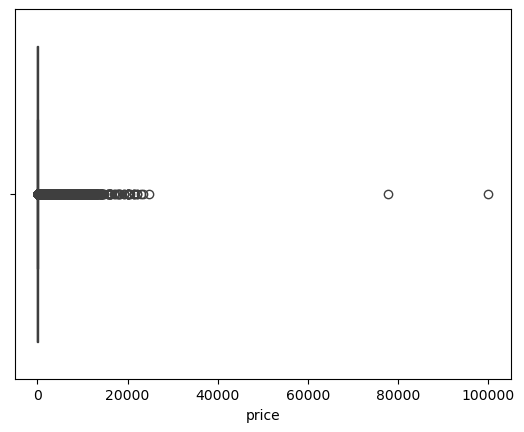

In [ ]:
sns.boxplot(x="price", data = pd.DataFrame(df["price"]))                            
#sns.boxplot(x="price", data = pd.DataFrame(df["price"][df["price"] <20000]))       # alternative, if you want to filter by price range
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?



**Conclusion part 3**
- 1. More than 50% of the ratings are equal to 0.0 -> I think most customers only review products if they are not satisfied with the product.
- 2. There is a wide variation in customers feedback (0.0 - 5.0, just as it is possible)
- 3. Skewness: 0.08 that's almost symmetrical
- 3. Kurtosis: -1.93 means it is platykurtic (negative excess kurtosis). With lighter tails and a flatter peak, what means fewer outliers
- 4. As already noted, most ratings are around 0.0. Ratings 1.0 to 3.0 are very rare, but there are more ratings between 4.0 and 5.0.

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [118]:
stars_mean = df["stars"].mean()
stars_median = df["stars"].median()
stars_mode = df["stars"].mode()

print(f"mean: {stars_mean}")
print(f"median: {stars_median}")
print(f"mode: {stars_mode}")

mean: 2.152836472966066
median: 0.0
mode: 0    0.0
Name: stars, dtype: float64


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [120]:
stars_var = df["stars"].var()
stars_std = df["stars"].std()
stars_range = df["stars"].max() - df["stars"].min()
#stars_min = df["stars"].min()
#stars_max = df["stars"].max()
stars_interquartile_range = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print(f"variance: {stars_var}")
print(f"standard deviation: {stars_std}")
print(f"range: {stars_range}")
#print(f"min: {stars_min}")
#print(f"max: {stars_max}")
print(f"interquartile range: {stars_interquartile_range}")


print(stars_std/stars_mean)
round(float(df["stars"].skew()), 2)

variance: 4.81743402976196
standard deviation: 2.1948653785054697
range: 5.0
interquartile range: 4.4
1.0195225722283952


0.08

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [123]:
print(round(float(df["stars"].skew()), 2))          # calculating the skewness
print(round(float(df["stars"].kurtosis()), 2))      # calculating the kurtosis


0.08
-1.93


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

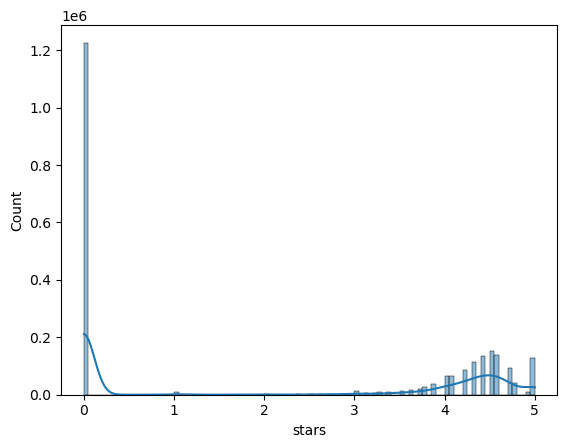

In [126]:
sns.histplot(x = df["stars"], bins=100, kde=True)

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 